# NOVA validation and pilot behavior

Here you can reproduce the scoring-accuracy results and the behavioral measures from our pilot studies. The notebook uses the de-identified data included in this package and does not make model calls. It covers the main evaluation of 1,225 inputs, the separate tutorial evaluation of 731 inputs, and the 38 completed NOVA negotiations used in the paper.

The accuracy calculations use the reviewed Type A and Type B decisions supplied with the spreadsheets. Those decisions reflect model-assisted review and researcher feedback, rather than a new independent human audit. They check whether ideas were missed or added; they do not independently verify every numerical mapping. See `Methods.md` for the full definitions.

In [1]:
from pathlib import Path
import json, warnings
import pandas as pd
from IPython.display import display, Image, Markdown
import analysis as nova
warnings.filterwarnings("ignore", message="Precision loss occurred")
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 80)
ROOT = Path.cwd()
assert (ROOT / "data/main_offers.json").exists(), "Run this notebook from its own folder."
outputs = nova.main()

## 1 Accuracy and scoring cost

An input passes when both error judgments are N. Type A means a meaningful idea was missed or improperly left unscored. Type B means an issue was added that the negotiator had not proposed. We report Wilson 95% confidence intervals at the offer level; several inputs can come from the same person.

The cost estimates use recorded token counts, including cached tokens, and the historical rates explained in `Methods.md`. They add all calls used to score an input. Scoring time covers the model calls, not time spent in the browser or preparing an offer.

In [2]:
accuracy = outputs["Accuracy_and_Costs.csv"].copy()
summary = pd.DataFrame({
    "Dataset": accuracy.dataset, "Scorer": accuracy.scorer,
    "Raw accuracy": accuracy.passed.astype(str) + "/" + accuracy.offers.astype(str),
    "Accuracy (95% CI)": [f"{100*r.accuracy:.2f}% ({100*r.ci_low:.2f}–{100*r.ci_high:.2f})" for r in accuracy.itertuples()],
    "Type A": accuracy.type_a, "Type B": accuracy.type_b,
    "US$ per 1,000 inputs": [f"{r.api_cost_per_1000_low:.2f}–{r.api_cost_per_1000_high:.2f}" for r in accuracy.itertuples()],
    "Mean seconds": accuracy.mean_scoring_seconds.round(2)})
display(summary)

,Dataset,Scorer,Raw accuracy,Accuracy (95% CI),Type A,Type B,"US$ per 1,000 inputs",Mean seconds
0,main,A1-low,1224/1225,99.92% (99.54–99.99),1,0,5.74–5.79,4.45
1,main,A1-high,1225/1225,100.00% (99.69–100.00),0,0,9.51–9.58,10.16
2,main,A2,1225/1225,100.00% (99.69–100.00),0,0,2.39–2.90,3.81
3,tutorial,A1-low,730/731,99.86% (99.23–99.98),1,0,2.95–2.99,4.20
4,tutorial,A1-high,730/731,99.86% (99.23–99.98),1,0,7.02–7.06,12.09
5,tutorial,A2,579/731,79.21% (76.12–81.99),146,9,0.74–0.82,3.77


### How the cost is calculated

For each call, we charge uncached input tokens at the input rate, cached input tokens at the cached rate, and output tokens at the output rate. We divide by one million because the rates are quoted per million tokens. We then add the calls for each input, average across inputs and multiply by 1,000.

The lower and upper estimates reflect the historical rate assumptions. A response reused during evaluation is not treated as a free call when estimating normal use. These figures estimate scoring costs; they are not a total of past invoices.

In [3]:
usage = pd.DataFrame(nova.read("api_usage.json"))
display(usage[["dataset", "scorer", "input_tokens", "cached_input_tokens", "output_tokens", "model_calls", "cost_lower_usd", "cost_upper_usd"]].groupby(["dataset", "scorer"]).sum().round(4))

input_tokens  cached_input_tokens  output_tokens  \
dataset  scorer                                                      
main     A1-high      34363036             34209576         792675   
         A1-low       34363036             34256510         339780   
         A2           12374336                    0         379756   
tutorial A1-high       1550823              1484820         485036   
         A1-low        1550823              1484820         187585   
         A2            2433074              1239781         232317   

                  model_calls  cost_lower_usd  cost_upper_usd  
dataset  scorer                                                
main     A1-high         1225         11.6546         11.7314  
         A1-low          1225          7.0365          7.0898  
         A2              1225          2.9306          3.5493  
tutorial A1-high          731          5.1308          5.1638  
         A1-low           731          2.1563          2.1893  
         A2               771          0.5422          0.6019

### Look at the errors

The spreadsheets contain every offer and response. This table shows only those judged to contain an error. Keep the exercise, offer ID and scorer together when finding a record, because IDs repeat across scorers and the two exercises.

In [4]:
errors = []
for dataset in ["main", "tutorial"]:
    review = pd.read_csv(ROOT / "data" / f"{dataset}_review.csv", keep_default_na=False)
    a = next(c for c in review if c.startswith("Type A"))
    b = next(c for c in review if c.startswith("Type B"))
    failed = review[(review[a] == "Y") | (review[b] == "Y")].copy()
    failed.insert(0, "Dataset", dataset)
    errors.append(failed)
errors = pd.concat(errors, ignore_index=True)
display(errors[["Dataset", "Offer ID", "Scorer Architecture", "Error reason"]])

,Dataset,Offer ID,Scorer Architecture,Error reason
0,main,o1148,A1-low,"The offer asks for a professional training budget. The response scores training participation, w..."
1,tutorial,o288,A1-low,“I have the right to cancel up to 2 weeks beforehand” specifies cancellation with notice. R1 unn...
2,tutorial,o295,A1-high,"The offer explicitly says the date “remains 15th of September,” referring to September 15, 2027 ..."
3,tutorial,o1,A2,"Missed setup access: “we need to get in there early” clearly requests early setup, but the respo..."
4,tutorial,o5,A2,"The offer requests 'cancellation without penalty up fee for up to 1 week before the event,' clea..."
...,...,...,...,...
150,tutorial,o708,A2,"Missed the date constraint ""it couldn't be any earlier than the 10th"": the response neither mean..."
151,tutorial,o713,A2,Misses the duration in “open for 24 hours”: records only “open” without capturing the 24-hour re...
152,tutorial,o715,A2,"The offer specifies “for 400 dollars,” but the response leaves Venue fee unscored and asks for t..."
153,tutorial,o719,A2,“Can the venue offer unlimited teas and coffees within this price?” clearly requests venue-provi...


## 2 How many trials and responses were included

A trial is an assigned pair, including pairs that did not complete the study. We use behavior from valid negotiations where both parties took part, even if a survey was not completed. The completed sample used in the paper excludes early quits. Survey comparisons require both questionnaires and both partners' answers to the measure being compared.

In [5]:
trials = pd.DataFrame(nova.read("trials.json"))
dyads, events, frequency = nova.recompute_behavior()
counts = trials.groupby("condition").agg(assigned_trials=("trial_id", "size"), valid_reciprocal=("included_behavior", "sum"), completed=("completed_negotiation", "sum"), both_surveys=("has_both_surveys", "sum"))
display(counts)
nova_people = set(trials.loc[trials.condition == "NOVA", "candidate"]) | set(trials.loc[trials.condition == "NOVA", "recruiter"])
print("NOVA distinct assigned participants:", len(nova_people - {""}))

,assigned_trials,valid_reciprocal,completed,both_surveys
condition,,,,
Fixed 9,53,42,41,41
NOVA,56,39,38,38


NOVA distinct assigned participants: 112


## 3 How issues developed during negotiation

Issue diversity counts the distinct issues mentioned across a pair's submitted offers. Additional diversity leaves out the three required issues: salary, work-expense budget and starting date.

An offer introduces an issue if it adds something not mentioned earlier in that negotiation. It counts as exploration if its issue set differs from the union of both parties' latest offers just beforehand. The opening offer is left out when calculating these rates.

The calculations below work through the recorded issue-to-option mappings again, rather than simply copying earlier summary figures.

In [6]:
completed_nova = dyads[(dyads.condition == "NOVA") & (dyads.early_quit == 0)]
additional = nova.mean_ci(completed_nova.nonrequired_issue_diversity)
print(f"Completed NOVA negotiations: {len(completed_nova)}")
print(f"Additional issues: mean {additional["mean"]:.2f}, SD {additional["sd"]:.2f}, 95% CI {additional["ci_low"]:.2f}–{additional["ci_high"]:.2f}")
print("Maximum total distinct issues:", completed_nova.issue_diversity.max())
print("Distinct nonrequired issues across completed NOVA negotiations:", len(frequency))
k = int(completed_nova.introduced_issue_after_opening.sum())
print(f"New issues after opening: {k}/{len(completed_nova)} ({100*k/len(completed_nova):.1f}%)")
display(pd.DataFrame([{ "Measure": m, **nova.mean_ci(completed_nova[m]) } for m in ["introduction_rate", "exploration_rate", "exploitation_rate"]]).round(4))
eligible = events[events.trial_id.isin(completed_nova.trial_id) & events.eligible]
print("Offer-weighted rates across eligible submitted offers:")
display(eligible[["introduction", "exploration", "exploitation"]].mean().to_frame("Rate"))

Completed NOVA negotiations: 38
Additional issues: mean 3.74, SD 2.15, 95% CI 3.03–4.44
Maximum total distinct issues: 13
Distinct nonrequired issues across completed NOVA negotiations: 19
New issues after opening: 22/38 (57.9%)


,Measure,n,mean,sd,ci_low,ci_high
0,introduction_rate,36,0.2081,0.3002,0.1065,0.3097
1,exploration_rate,36,0.4207,0.3539,0.3009,0.5404
2,exploitation_rate,36,0.8289,0.2257,0.7525,0.9052


Offer-weighted rates across eligible submitted offers:


,Rate
introduction,0.106667
exploration,0.446667
exploitation,0.723333


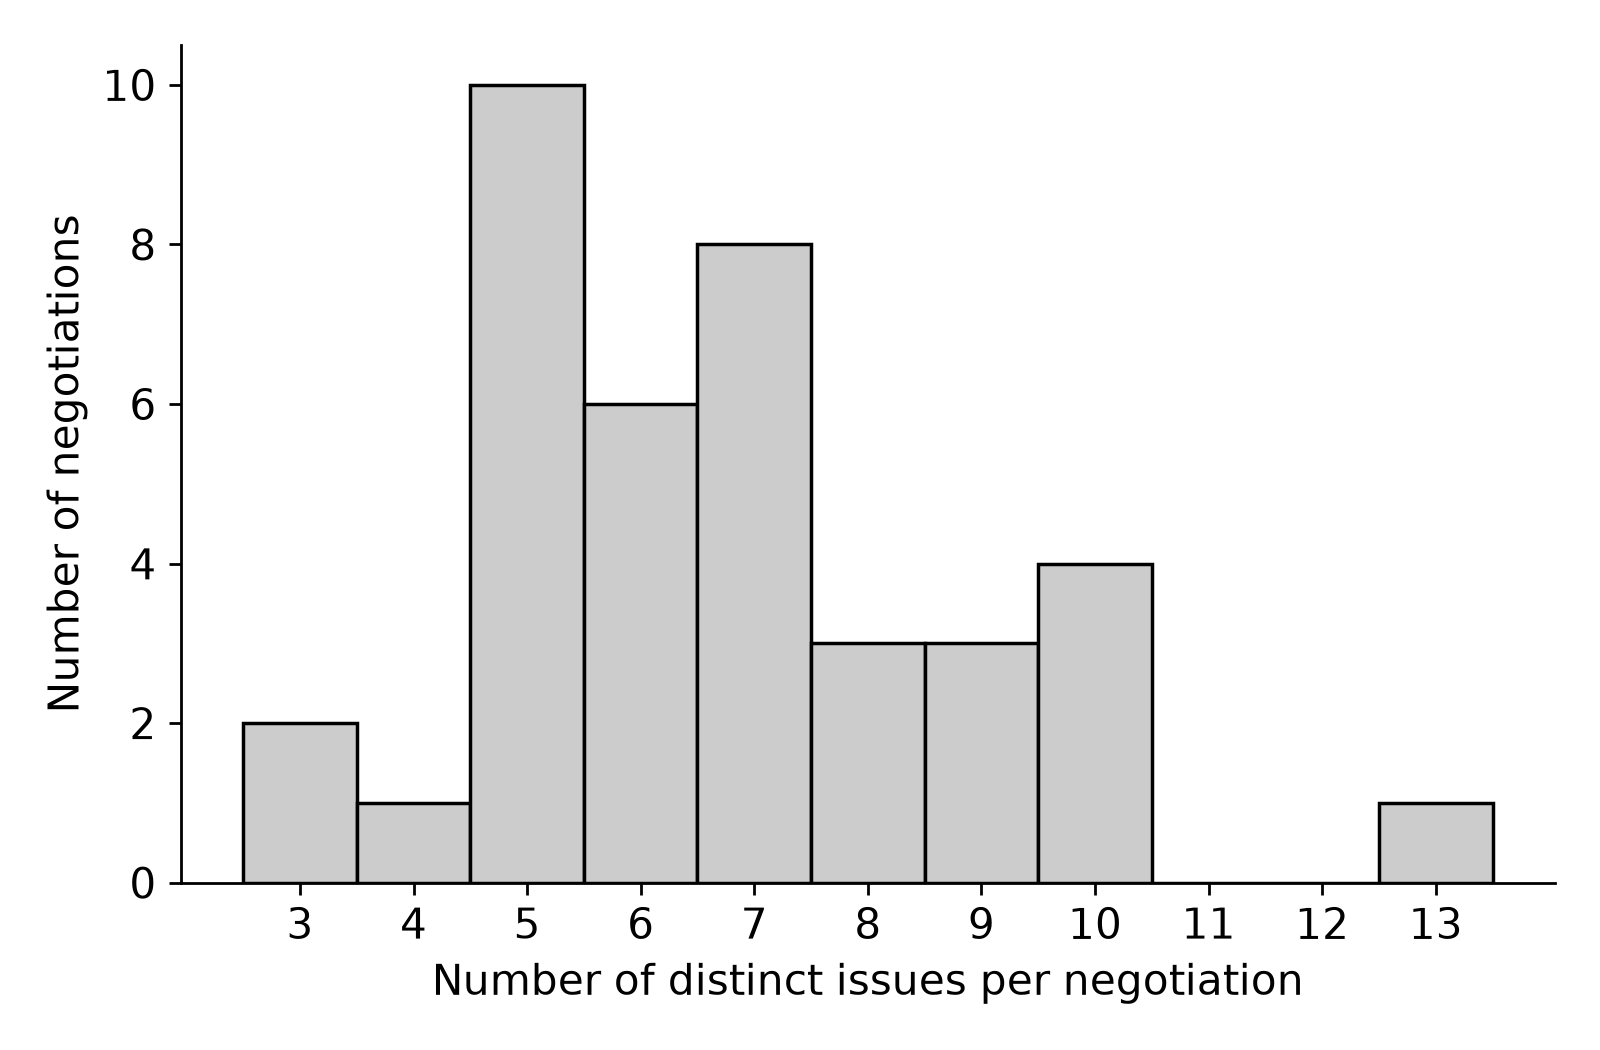

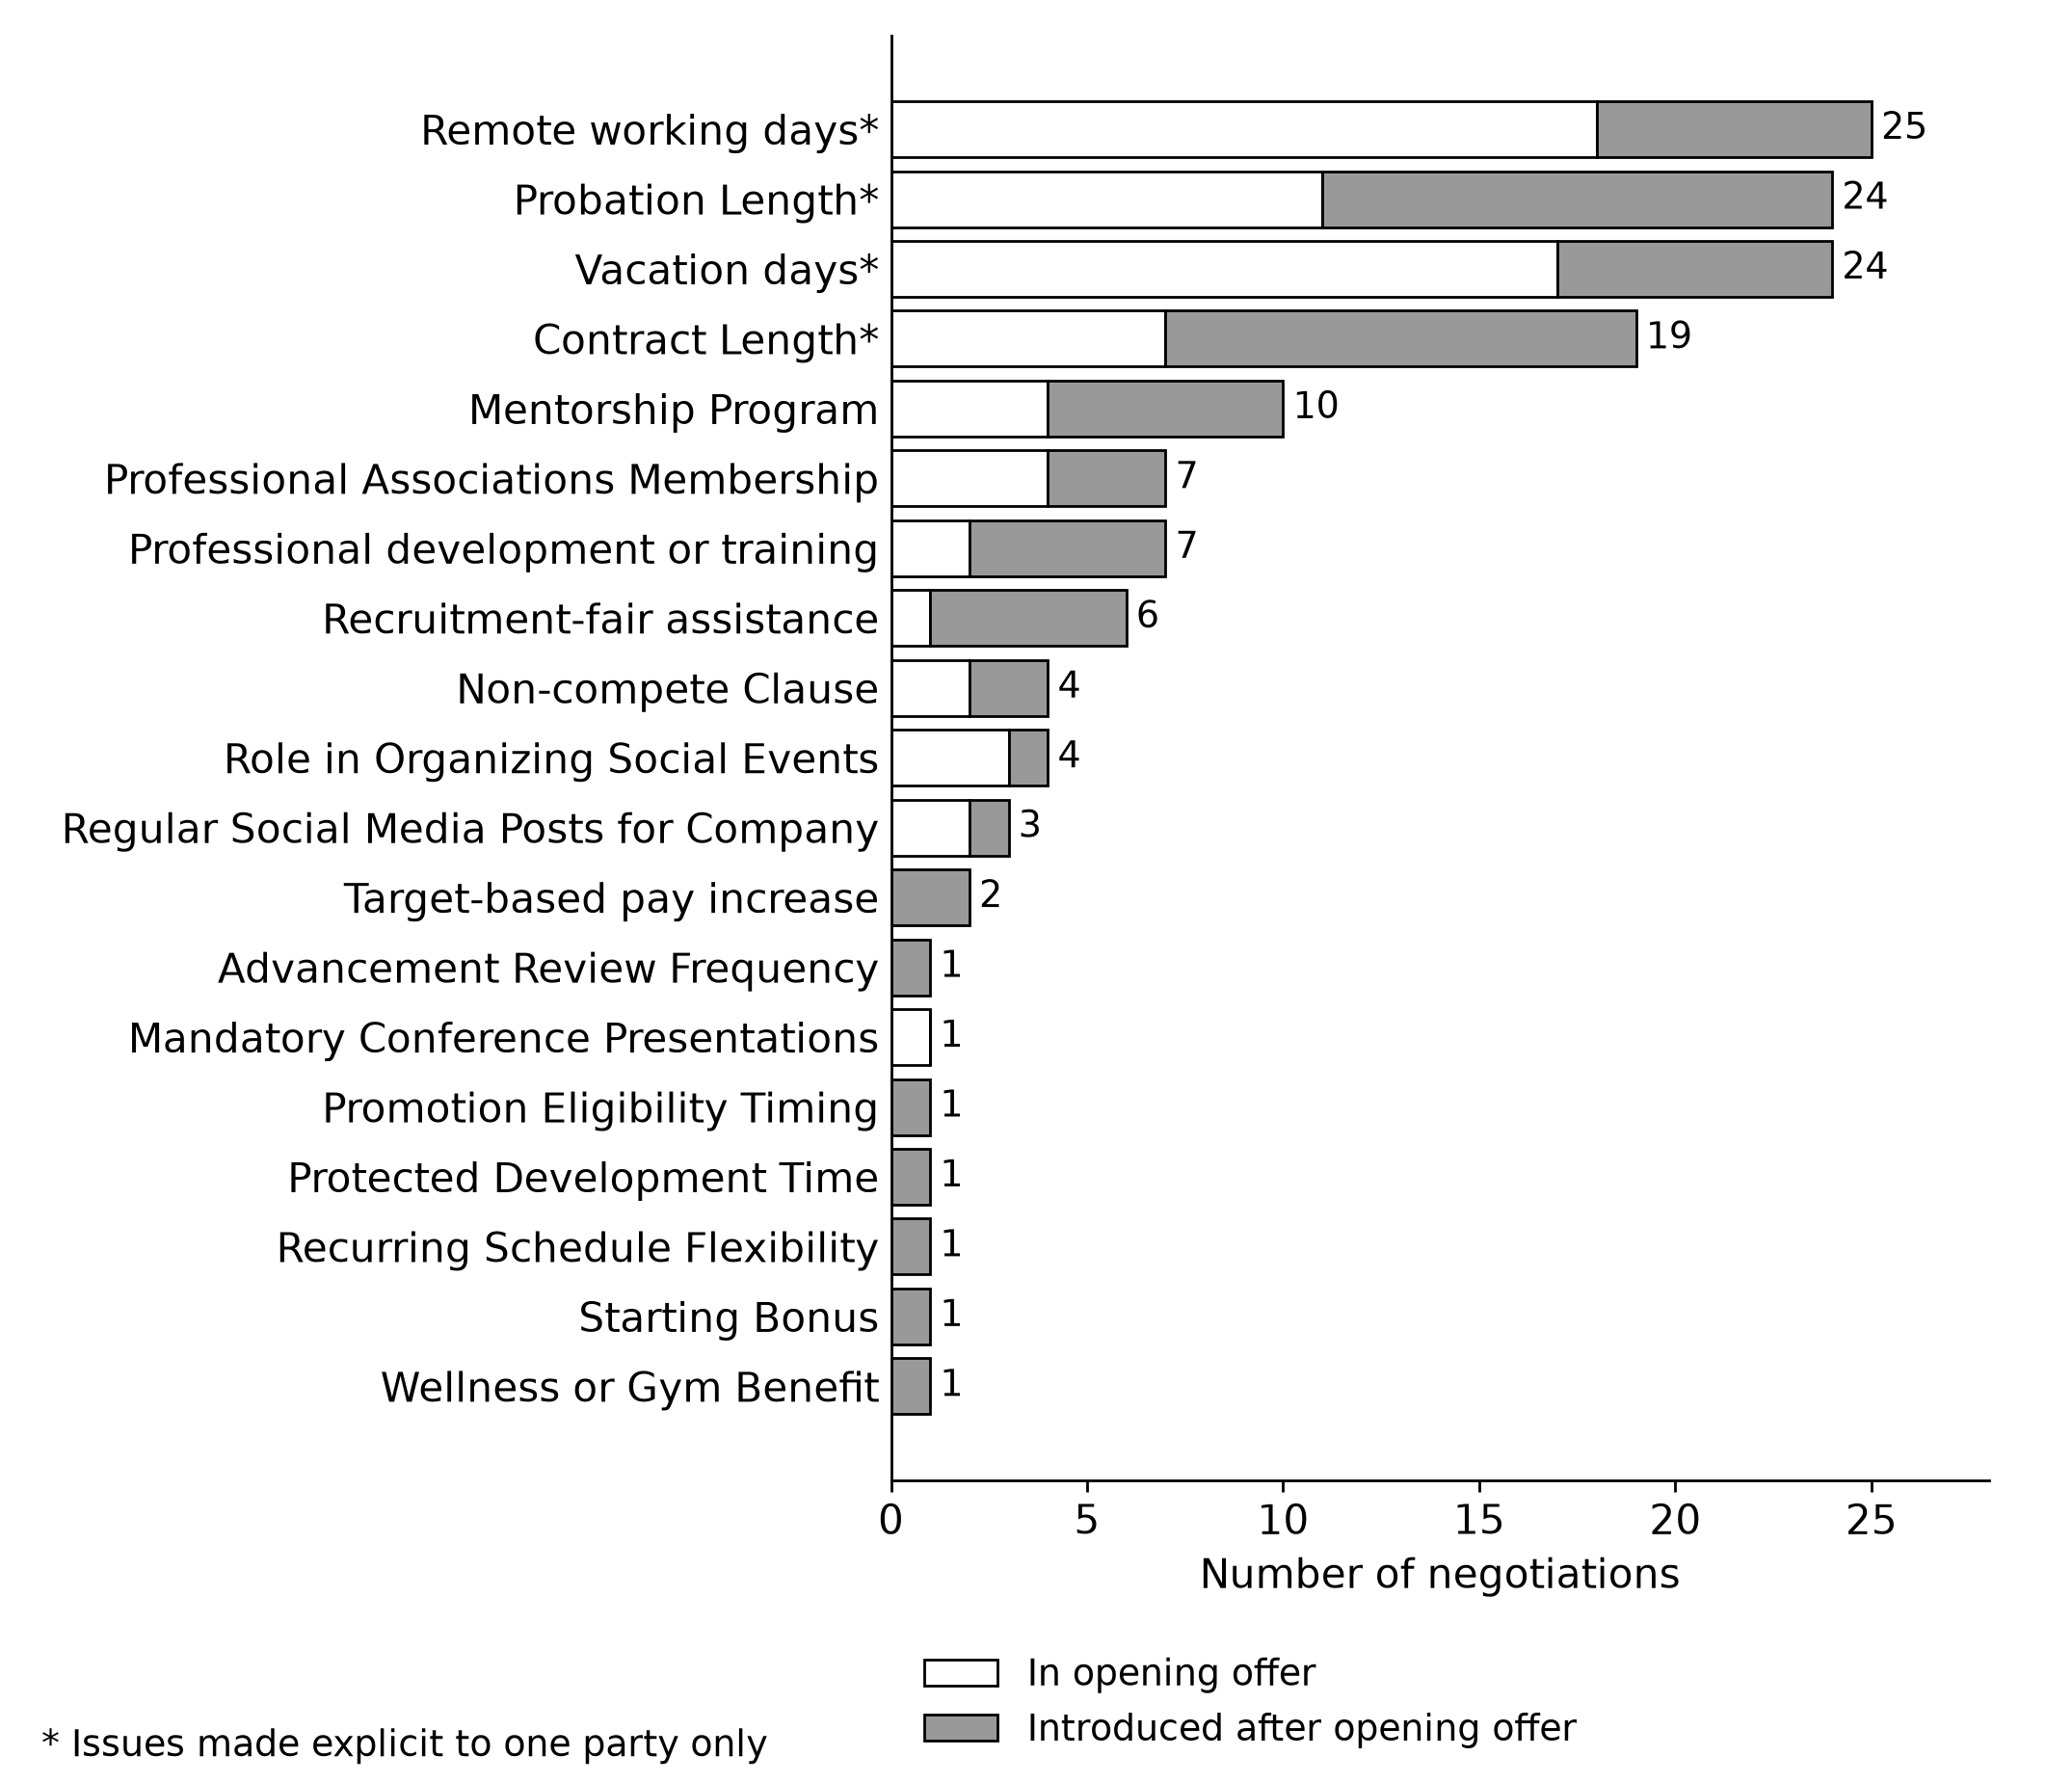

,issue,opening,introduced_later,total
0,Remote Working Days,18,7,25
1,Probation Length,11,13,24
2,Vacation Days,17,7,24
3,Contract Length,7,12,19
4,Mentorship Program,4,6,10
5,Professional Associations Membership,4,3,7
6,Professional Training Program,2,5,7
7,Role in Recruitment Fair,1,5,6
8,Non-compete Clause,2,2,4
9,Role in Organizing Social Events,3,1,4


In [7]:
nova.figures(dyads, frequency)
display(Image(filename=str(ROOT / "figures/Issue_Diversity.png"), width=650))
display(Image(filename=str(ROOT / "figures/Nonrequired_Issues.png"), width=900))
display(frequency.reset_index(drop=True))

## 4 Comparing conditions and agreement rates

The behavioral comparisons use completed, valid negotiations. Each pair contributes one observation. We show means, SDs, confidence intervals and exploratory Welch p values, without adjustment for multiple tests. The sample can vary by measure. A p value may be undefined if there is no variation to estimate.

Agreement rates are shown both for valid negotiations and for the completed sample. An agreement can have a score of zero for either party. The share completing the study is a separate measure with a different denominator.

In [8]:
display(outputs["Behavioral_Comparisons.csv"].round(4))
display(outputs["Agreement_Rates.csv"].round(4))

,measure,condition,n,mean,sd,ci_low,ci_high,p_value
0,offer_count,NOVA,38,8.8947,11.3704,5.1574,12.6321,0.1715
1,offer_count,Fixed 9,41,6.0488,5.7834,4.2233,7.8742,0.1715
2,issue_diversity,NOVA,38,6.7368,2.1521,6.0295,7.4442,0.0000
3,issue_diversity,Fixed 9,41,9.0000,0.0000,9.0000,9.0000,0.0000
4,nonrequired_issue_diversity,NOVA,38,3.7368,2.1521,3.0295,4.4442,0.0000
5,nonrequired_issue_diversity,Fixed 9,41,6.0000,0.0000,6.0000,6.0000,0.0000
6,exploration_rate,NOVA,36,0.4207,0.3539,0.3009,0.5404,0.0000
7,exploration_rate,Fixed 9,39,0.0000,0.0000,0.0000,0.0000,0.0000
8,introduction_rate,NOVA,36,0.2081,0.3002,0.1065,0.3097,0.0002
9,introduction_rate,Fixed 9,39,0.0000,0.0000,0.0000,0.0000,0.0002


,population,condition,agreements,negotiations,rate,ci_low,ci_high,p_value
0,Valid reciprocal negotiations,Fixed 9,41,42,0.9762,0.8768,0.9958,0.3474
1,Valid reciprocal negotiations,NOVA,36,39,0.9231,0.7968,0.9735,0.3474
2,Completed negotiations,Fixed 9,41,41,1.0000,0.9143,1.0000,0.2282
3,Completed negotiations,NOVA,36,38,0.9474,0.8271,0.9854,0.2282


## 5 What participants reported

Subjective value averages Q1–Q16, with Q3 and Q5 reversed. Creative engagement uses Q20–Q24 on a five-point scale; creative confidence uses Q25–Q27 on a seven-point scale. We average the two partners' answers before comparing conditions, and both need a usable answer for that measure.

Q29 asks whether participants felt stuck. It is not a separate validated measure of impasse. The full questions and response choices are in section 2 of the repository. We could not reliably measure exact tutorial duration, so preparation time is labelled as an approximation.

In [9]:
people, survey_stats = nova.surveys()
question_schema = json.loads((ROOT.parent / "2_Exercise_Materials/questionnaires/Post_Negotiation_Analysis_Schema.json").read_text(encoding="utf-8"))
questions = question_schema.get("questions", [])
if isinstance(questions, dict):
    question_labels = {k: (v.get("label", str(v)) if isinstance(v, dict) else str(v)) for k, v in questions.items()}
else:
    question_labels = {q["id"]: q.get("label", "") for q in questions}
survey_stats["measure"] = survey_stats.measure.map(lambda x: x + ": " + question_labels[x] if x in question_labels else x)
display(survey_stats.round(4))
print("Eligible respondent records:", len(people))
print("Eligible both-survey dyads:", people.trial_id.nunique())

,measure,condition,n,mean,sd,ci_low,ci_high,p_value
0,Subjective value (Q1–Q16),NOVA,38,5.0329,0.5858,4.8404,5.2255,0.4795
1,Subjective value (Q1–Q16),Fixed 9,41,4.9116,0.9080,4.6250,5.1982,0.4795
2,Creative engagement (Q20–Q24),NOVA,38,3.6974,0.5385,3.5204,3.8744,0.2456
3,Creative engagement (Q20–Q24),Fixed 9,41,3.5610,0.4939,3.4051,3.7169,0.2456
4,Creative confidence (Q25–Q27),NOVA,38,5.0351,1.0677,4.6842,5.3860,0.6681
5,Creative confidence (Q25–Q27),Fixed 9,41,4.9390,0.9012,4.6546,5.2235,0.6681
6,Q18: The negotiation was realistic,NOVA,38,5.3158,1.1236,4.9465,5.6851,0.4653
7,Q18: The negotiation was realistic,Fixed 9,41,5.1341,1.0725,4.7956,5.4727,0.4653
8,Q17: Imagine being in the role,NOVA,38,5.2763,1.3239,4.8412,5.7115,0.6641
9,Q17: Imagine being in the role,Fixed 9,41,5.3902,0.9521,5.0897,5.6907,0.6641


Eligible respondent records: 158
Eligible both-survey dyads: 79


## 6 Checks and details to keep in mind

The supplied review decisions reproduce the main and tutorial accuracy figures. This does not mean that all judgments were independent of development, or that a model would return exactly the same answers if called again.

We also show two differences between the historical files and later descriptions: the frozen scoring table has no coffee entry, and some older agreement settings require strictly positive scores even though the analysis rule accepts zero. These are noted explicitly rather than quietly changed.

In [10]:
display(nova.reproduction_checks(accuracy, dyads))
print("No API calls were made by this analysis.")

,check,result
0,Main and tutorial accuracy counts,Match reviewed workbook
1,Completed NOVA negotiations,38
2,Mean additional issues,3.736842
3,New issues after opening,22/38
4,Coffee scoring-table entry,Absent from frozen 215-issue snapshot; manuscript statement about a later addition is not reprod...
5,Agreement eligibility,Analysis uses both scores >= 0. Historical JSON includes contradictory legacy > 0 metadata; it i...
6,Primary accuracy scope,Type A and Type B. Historical option-mapping flags are not independently verified by this measure.


No API calls were made by this analysis.
